# A general model of an aerosol

tracks the general reaction
 
 - a = aerosol
 - b = gas
 - c = product 1 (not very volatile)
 - d = product 2 (very volatile)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.integrate import solve_ivp


In [2]:
# starting number of species

a = 10
b = 20
c = 0
d = 0

In [3]:
# ozone diffusion
# tracks ozones movement from bulk to air to gas surrounding aerosol
# relatively slow

kdiff = 0.001

In [4]:
# ozone condensation into aerosol
# slightly slower than diffusion

kcond = 0.0005

In [5]:
# ozone reaction with aerosol, inside aerosol
# relatively fast reaction

kreact = 0.01

In [6]:
# evaporation rate for b, c, d

kb_evap = 0.0005
kc_evap = 0.00005
kd_evap = 0.001

In [7]:
t_end = 12500

def kinetics(t, y):
    bbulk, bgas, bliq, a, c, d = y

    rate1 = kdiff * bbulk
    rate2 = kcond * bgas
    rate3 = kreact * a * bliq
    rate4 = kb_evap * bliq
    rate5 = kc_evap * c
    rate6 = kd_evap * d

    # Track changes as if we are inside the aerosol
    dbbulk_dt = - rate1 
    dbgas_dt = rate1 - rate2
    dbliq_dt = rate2 - rate3 - rate4
    da_dt = - rate3
    dc_dt = rate3 - rate5
    dd_dt = rate3 - rate6

    return[dbbulk_dt, dbgas_dt, dbliq_dt, da_dt, dc_dt, dd_dt]

y0 = [b,0,0,a, c, d]

sol = solve_ivp(kinetics,
                (0.0, t_end),
                y0,
                t_eval=np.linspace(0, t_end, 200),
                rtol=1e-8, atol=1e-10)

t = sol.t
bbulk, bgas, bliq, a, c, d = sol.y




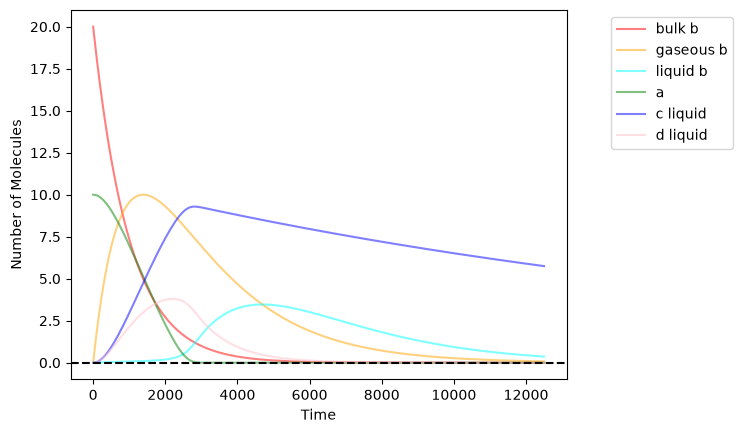

In [8]:
plt.plot(t, bbulk, label="bulk b", color ='red', alpha=0.5)
plt.plot(t, bgas, label="gaseous b", color ='orange', alpha=0.5)
plt.plot(t, bliq, label="liquid b", color ='cyan', alpha=0.5)
plt.plot(t, a, label="a", color ='green', alpha=0.5)
plt.plot(t, c, label="c liquid", color ='blue', alpha=0.5)
plt.plot(t, d, label="d liquid", color ='pink', alpha=0.5)
plt.axhline(y=0, color="black", linestyle='dashed')
plt.xlabel("Time")
plt.ylabel("Number of Molecules")
plt.legend(bbox_to_anchor=(1.35,1.0))
plt.show()

we need to track conc of b as different phases

do we need to track bgas return to surrounding gas?

i dont think so cos it will react